In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.markers as mmarkers
from matplotlib_venn import venn2
import seaborn as sns
import scipy

from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils, seed_utils

import main_analysis as ma
import paths

# Matplotlib settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# Font
font_path = '/home/alishd/.fonts/Avenir.ttc'
avenir_font = fm.FontProperties(fname=font_path)
mpl.rcParams['font.family'] = avenir_font.get_name()
ttc = fm.get_font(font_path)
print("Font name from TTC:", ttc.family_name)
print("Style:", ttc.style_name)

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/postvss25'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KANWISHER_LOCALIZER_DIR = paths.KANWISHER_LOCALIZER_DIR

Font name from TTC: Avenir
Style: Book


In [2]:
# Utils

def get_shades(hex_color, n=5, lighten_limit=0.25, darken_limit=0.75):
    """
    Generate n shades around a base hex_color.
    Base sits in the middle, lighter tints above, darker shades below.
    
    lighten_limit: how much lighter the lightest color can get (0-1)
    darken_limit: how much darker the darkest color can get (0-1)
    """
    rgb = np.array(mcolors.to_rgb(hex_color))
    colors = []
    mid = (n - 1) / 2
    
    for i in range(n):
        factor = (i - mid) / mid  # ranges -1..1
        if factor < 0:
            # lighter: move towards white but limited
            new_rgb = rgb + (1 - rgb) * (-factor * lighten_limit)
        else:
            # darker: move towards black but limited
            new_rgb = rgb * (1 - factor * darken_limit)
        colors.append(np.clip(new_rgb, 0, 1))
    return colors

# Fig 4: Venn diagrams

In [86]:
frois = ['FFA', 'PPA', 'EBA']
all_models = ma.get_all_models()
tthreshold = 7

Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Using cached ./models


Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


## Stats

In [4]:
for fidx, froi in enumerate(frois):
    best_layers = ma.get_froi_models_layers(froi, froi)
    set_num_units = [] # (only_gs, only_kw, both, total, iou)
    for model_name, model in all_models.items():
        layer = best_layers[model_name]
        gs_loc_froi_mask = localizer.get_froi_mask(
            GRILLSPECTOR_LOCALIZER_DIR, 'grillspector', MODELS_DIR,
            model, layer, froi, tthreshold
        )
        kw_loc_froi_mask = localizer.get_froi_mask(
            KANWISHER_LOCALIZER_DIR, 'kanwisher', MODELS_DIR,
            model, layer, froi, tthreshold
        )
        a = gs_loc_froi_mask
        b = kw_loc_froi_mask
        total = a.numel()
        only_a = torch.logical_and(a, ~b).sum().item()
        only_b = torch.logical_and(~a, b).sum().item()
        both   = torch.logical_and(a, b).sum().item()
        neither = torch.logical_and(~a, ~b).sum().item()
        intersection = torch.logical_and(a, b).sum().float()
        union = torch.logical_or(a, b).sum().float()
        iou = (intersection / union).item()
        set_num_units.append((only_a, only_b, both, total, iou))
    set_num_units = np.array(set_num_units)
    ious = set_num_units[:, 4]
    print(f'{froi} mean IoU: {ious.mean():.3f} +/- {ious.std():.3f}, median: {np.median(ious):.3f}')

FFA mean IoU: 0.188 +/- 0.071, median: 0.192
PPA mean IoU: 0.015 +/- 0.017, median: 0.009
EBA mean IoU: 0.093 +/- 0.064, median: 0.084


## Plot

In [88]:
savefig = True
plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

# Venn diagram
fig1, axs1 = plt.subplots(1, len(frois), figsize=(5*len(frois), 5*1), dpi=300)
# Bar plot for percentage of units in each set
fig2, axs2 = plt.subplots(1, len(frois), figsize=(5*len(frois), 5*1), dpi=300)
fig2_ylims = {
    'FFA': (0, 10),
    'PPA': (0, 20),
    'EBA': (0, 4)
}
# Bar plot for IoU
fig3, axs3 = plt.subplots(1, len(frois), figsize=(5*len(frois), 5*1), dpi=300)

# venn_data = []
# for fidx, froi in enumerate(frois):
#     best_layers = ma.get_froi_models_layers(froi, froi)
#     froi_data = []
#     for model_name, model in all_models.items():
#         layer = best_layers[model_name]
#         gs_loc_froi_mask = localizer.get_froi_mask(
#             GRILLSPECTOR_LOCALIZER_DIR, 'grillspector', MODELS_DIR,
#             model, layer, froi, tthreshold
#         )
#         kw_loc_froi_mask = localizer.get_froi_mask(
#             KANWISHER_LOCALIZER_DIR, 'kanwisher', MODELS_DIR,
#             model, layer, froi, tthreshold
#         )
#         a = gs_loc_froi_mask
#         b = kw_loc_froi_mask
#         total = a.numel()
#         only_a = torch.logical_and(a, ~b).sum().item()
#         only_b = torch.logical_and(~a, b).sum().item()
#         both   = torch.logical_and(a, b).sum().item()
#         froi_data.append(
#             [
#                 only_a / total * 100,
#                 only_b / total * 100,
#                 both / total * 100
#             ]
#         )
#     froi_data = np.array(froi_data)
#     # Calculate the median percentage of units in each set across models
#     only_a = np.median(froi_data[:, 0]).item()
#     only_b = np.median(froi_data[:, 1]).item()
#     both   = np.median(froi_data[:, 2]).item()
#     venn_data.append([only_a, only_b, both])
# venn_data = np.array(venn_data)
# venn_data = venn_data/venn_data.sum()

for fidx, froi in enumerate(frois):
    best_layers = ma.get_froi_models_layers(froi, froi)
    set_num_units = [] # (only_gs, only_kw, both, total, iou)
    for model_name, model in all_models.items():
        layer = best_layers[model_name]
        gs_loc_froi_mask = localizer.get_froi_mask(
            GRILLSPECTOR_LOCALIZER_DIR, 'grillspector', MODELS_DIR,
            model, layer, froi, tthreshold
        )
        kw_loc_froi_mask = localizer.get_froi_mask(
            KANWISHER_LOCALIZER_DIR, 'kanwisher', MODELS_DIR,
            model, layer, froi, tthreshold
        )
        a = gs_loc_froi_mask.cpu()
        b = kw_loc_froi_mask.cpu()
        total = a.numel()
        only_a = torch.logical_and(a, ~b).sum().item()
        only_b = torch.logical_and(~a, b).sum().item()
        both   = torch.logical_and(a, b).sum().item()
        neither = torch.logical_and(~a, ~b).sum().item()
        intersection = torch.logical_and(a, b).sum().float()
        union = torch.logical_or(a, b).sum().float()
        iou = (intersection / union).item()
        set_num_units.append((only_a, only_b, both, total, iou))
    set_num_units = np.array(set_num_units)
    
    # Fig 1: Venn Diagram
    # Calculate the median percentage of units in each set across models
    only_a = np.median(set_num_units[:, 0] / set_num_units[:, 3]) * 100
    only_b = np.median(set_num_units[:, 1] / set_num_units[:, 3]) * 100
    both   = np.median(set_num_units[:, 2] / set_num_units[:, 3]) * 100
    # plot the Venn diagram
    venn2_fig = venn2(
        # subsets = venn_data[fidx],
        # normalize_to = venn_data.sum().item()/15,
        subsets=(only_a, only_b, both),
        set_labels=('Stigliani et al., 2015', 'Pitcher et al., 2011'),
        set_colors=('skyblue', 'lightgreen'),
        alpha=0.7, ax=axs1[fidx]
    )
    # Replace counts with formatted percentages
    for lidx, (label, count) in enumerate(zip(venn2_fig.subset_labels, (only_a, only_b, both))):
        if label:  # might be None if subset is empty
            label.set_text(f"{count:.2f}%")  # .2f formatting
            if lidx == 2 and froi == 'PPA':
                label.set_y(label.get_position()[1] + 0.1)  # Adjust position for better visibility
    # Set title for the Venn diagram
    axs1[fidx].set_title(froi)
    axs1[fidx].set_aspect('equal')
    # axs1[fidx].set_xlim(-1.1, 1.1)
    # axs1[fidx].set_ylim(-1.1, 1.1)

    # Fig 2: Bar plot for percentage of units in each set
    only_as = set_num_units[:, 0] / set_num_units[:, 3] * 100
    only_bs = set_num_units[:, 1] / set_num_units[:, 3] * 100
    boths   = set_num_units[:, 2] / set_num_units[:, 3] * 100
    medians = np.array([np.median(only_as), np.median(boths), np.median(only_bs)])
    sems = np.array([
        scipy.stats.sem(only_as),
        scipy.stats.sem(boths),
        scipy.stats.sem(only_bs),
    ])
    # Plot connecting lines
    x_offset = 0.05
    alpha = 0.5
    markersize = 25
    x = [0, 0.3, 0.6]
    bar_width = 0.2
    # Connect points with a line
    for i in range(len(only_as)):
        axs2[fidx].plot(
            np.array(x) - x_offset, [only_as[i], boths[i], only_bs[i]], '.-',
            color='red', alpha=0.2, linewidth=0.5, zorder=1
        )
    # Plot the bars
    axs2[fidx].bar(
        x, medians, yerr=sems, width=bar_width, 
        color=['red', 'red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1}
    )
    # y=0 line
    axs2[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)
    # Plot properties
    axs2[fidx].spines['top'].set_visible(False)
    axs2[fidx].spines['right'].set_visible(False)
    axs2[fidx].spines['left'].set_position(('outward', 5))
    axs2[fidx].spines['bottom'].set_position(('outward', 5))
    axs2[fidx].set_xticks(x)
    axs2[fidx].set_xticklabels(
        ['Stigliani et al., 2015', 'Both', 'Pitcher et al., 2011'], rotation=45
    )
    axs2[fidx].set_ylabel('Percentage of units (%)')
    axs2[fidx].set_title(froi)
    # set a total of 5 yticks between 0 and closest integer below the maximum percentage
    ylim = fig2_ylims[froi]
    yticks = np.linspace(ylim[0], ylim[1], 4)
    axs2[fidx].set_yticks(yticks)
    axs2[fidx].set_ylim(ylim)
    axs2[fidx].set_yticklabels([f"{int(t)}" for t in yticks])
    axs2[fidx].spines['left'].set_bounds(ylim)

    # Fig 3: Bar plot for IoU
    ious = set_num_units[:, 4]
    iou_median = np.median(ious)
    iou_sem = scipy.stats.sem(ious)
    # Plot individual IoU values
    x_offset = 0.05
    axs3[fidx].plot(
        np.zeros_like(ious) - x_offset, ious, 'o', color='red', alpha=0.2, 
    )
    # Plot the IoU bar
    axs3[fidx].bar(
        [0], [iou_median], yerr=iou_sem, width=0.2, 
        color='red', alpha=0.25, capsize=0, error_kw={'linewidth': 1}
    )
    # Plot properties
    # set ylim to [0, 1]
    axs3[fidx].set_ylim(-0.01, 1)
    axs3[fidx].spines['top'].set_visible(False)
    axs3[fidx].spines['right'].set_visible(False)
    axs3[fidx].spines['left'].set_position(('outward', 5))
    axs3[fidx].spines['bottom'].set_position(('outward', 5))
    axs3[fidx].set_xlim(-0.3, 0.3)
    axs3[fidx].set_xticks([0])
    axs3[fidx].set_xticklabels([froi])
    yticks = np.linspace(0, 1, 5)
    axs3[fidx].set_yticks(yticks)
    axs3[fidx].set_yticklabels([f"{t:.2f}" for t in yticks])
    axs3[fidx].set_ylabel('IoU')
    
if savefig:
    fig1.savefig(f'{plot_dir}/fig4_localizer_intersections_venn.pdf', bbox_inches='tight')
    # fig2.savefig(f'{plot_dir}/fig4_sup2_bar_plot.pdf', bbox_inches='tight')
    # fig3.savefig(f'{plot_dir}/fig4_iou_bar_plot.pdf', bbox_inches='tight')
else:
    plt.show()
plt.close(fig1)
plt.close(fig2)
plt.close(fig3)

# Fig 4: % units / num voxels vs. t-thresholds

In [ ]:
all_models = ma.get_all_models()
tthresholds = [3, 5, 7, 9, 11]
subjects = [1, 2, 3, 4, 5, 6, 7, 8]
frois = ['FFA', 'PPA', 'EBA']
model_localizer = 'grillspector'
model_localizer_dir = GRILLSPECTOR_LOCALIZER_DIR

Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Using cached ./models


Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


In [81]:
savefig = True

cmap = plt.get_cmap('Accent')
colors = [cmap(i) for i in range(cmap.N)]

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

# Line plot
fig, axs = plt.subplots(1, 2, figsize=(5*2, 5*1), dpi=300)

axs[0].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)
axs[1].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

vox_plt_idx, unit_plt_idx = 0, 1

# Subplot: % category-selective units across t-thresholds
for fidx, froi in enumerate(frois):
    froi_t_medians = []
    froi_t_sems = []
    for tidx, tthreshold in enumerate(tthresholds):
        froi_t_num_voxels = []
        for subject in subjects:
            # Get the fROI mask for the subject and tthreshold
            subject_froi_mask, _ = nsd.get_froi_mask(
                NSD_DIR, froi, subject, tthreshold
            )
            froi_voxels = subject_froi_mask.sum().item()
            froi_t_num_voxels.append(froi_voxels)
        froi_t_num_voxels = np.array(froi_t_num_voxels)
        froi_t_median = np.median(froi_t_num_voxels)
        froi_t_medians.append(froi_t_median)
        froi_t_sem = scipy.stats.sem(froi_t_num_voxels)
        froi_t_sems.append(froi_t_sem)
    # Plot the line with dots and errorbars for this froi
    froi_color = colors[fidx]
    axs[vox_plt_idx].plot(
        tthresholds, froi_t_medians, '.-', color=froi_color, linewidth=1, alpha=1,
        label=f'{froi}'
    )
    axs[vox_plt_idx].errorbar(
        tthresholds, froi_t_medians, yerr=froi_t_sems,
        fmt='none', ecolor=froi_color, elinewidth=1, alpha=0.75, capsize=0
    )
    axs[vox_plt_idx].set_xlabel('Brain t-threshold')
    axs[vox_plt_idx].set_ylabel(f'Number of voxels (Median ± SEM)')
    axs[vox_plt_idx].spines['top'].set_visible(False)
    axs[vox_plt_idx].spines['right'].set_visible(False)
    axs[vox_plt_idx].spines['left'].set_position(('outward', 5))
    axs[vox_plt_idx].spines['bottom'].set_position(('outward', 5))
    axs[vox_plt_idx].set_yticks([0, 350, 700, 1050, 1400, 1750])
    axs[vox_plt_idx].spines['left'].set_bounds(0, 1750)
    axs[vox_plt_idx].set_ylim((0, 1800))
    axs[vox_plt_idx].set_xticks(tthresholds)
    axs[vox_plt_idx].spines['bottom'].set_bounds(3, 11)
# Legend
axs[vox_plt_idx].legend(
    loc='upper right', fontsize=10,
    title='fROI', title_fontsize='13', frameon=False
)

# Subplot: number of voxels units across t-thresholds
for fidx, froi in enumerate(frois):
    best_layers = ma.get_froi_models_layers(froi, froi)
    froi_t_medians = []
    froi_t_sems = []
    for tidx, tthreshold in enumerate(tthresholds):
        froi_t_percent_units = []
        for model_name, model in all_models.items():
            # Get the fROI mask for the model and tthreshold
            layer = best_layers[model_name]
            model_froi_mask = localizer.get_froi_mask(
                model_localizer_dir, model_localizer, MODELS_DIR,
                model, layer, froi, tthreshold
            )
            total_units = model_froi_mask.numel()
            froi_units = model_froi_mask.sum().item()
            percent_units = froi_units / total_units * 100
            froi_t_percent_units.append(percent_units)
        froi_t_percent_units = np.array(froi_t_percent_units)
        froi_t_median = np.median(froi_t_percent_units)
        froi_t_medians.append(froi_t_median)
        froi_t_sem = scipy.stats.sem(froi_t_percent_units)
        froi_t_sems.append(froi_t_sem)
    # Plot the line with dots and errorbars for this froi
    froi_color = colors[fidx]
    if froi == 'FFA':
        label = 'face-selective'
    elif froi == 'PPA':
        label = 'scene-selective'
    else:
        label = 'body-selective'
    axs[unit_plt_idx].plot(
        tthresholds, froi_t_medians, '.-', color=froi_color, linewidth=1, alpha=1,
        label=label
    )
    axs[unit_plt_idx].errorbar(
        tthresholds, froi_t_medians, yerr=froi_t_sems,
        fmt='none', ecolor=froi_color, elinewidth=1, alpha=0.75, capsize=0
    )
    axs[unit_plt_idx].set_xlabel('ANN t-threshold')
    axs[unit_plt_idx].set_ylabel(f'% category-selective units (Median ± SEM)')
    axs[unit_plt_idx].spines['top'].set_visible(False)
    axs[unit_plt_idx].spines['right'].set_visible(False)
    axs[unit_plt_idx].spines['left'].set_position(('outward', 5))
    axs[unit_plt_idx].spines['bottom'].set_position(('outward', 5))
    axs[unit_plt_idx].set_yticks([0, 2, 4, 6, 8])
    axs[unit_plt_idx].spines['left'].set_bounds(0, 8)
    axs[unit_plt_idx].set_ylim((0, 8.5))
    axs[unit_plt_idx].set_xticks(tthresholds)
    axs[unit_plt_idx].spines['bottom'].set_bounds(3, 11)
# Legend
axs[unit_plt_idx].legend(
    loc='upper right', fontsize=10,
    title='Category', title_fontsize='13', frameon=False
)

if savefig:
    fig.savefig(f'{plot_dir}/fig4_unitsvoxels_vs_tthresholds.pdf', bbox_inches='tight')
else:
    plt.show()
plt.close(fig)

# IoU: Null tests

## Dev

In [ ]:
seed_utils.seed_everything(42)
iou_df_path = f'{RESULTS_DIR}/localizer_ious.csv'
ious_df = []
# Variables
tthreshold = 7
frois = ['FFA', 'PPA', 'EBA']
n_bootstrap = 5
localizers_name_dir = {
    'grillspector': GRILLSPECTOR_LOCALIZER_DIR,
    'kanwisher': KANWISHER_LOCALIZER_DIR
}
all_models = ma.get_all_models()

Using cache found in /home/alishd/.cache/torch/hub/harvard-visionlab_open_ipcl_main


/home/alishd/.cache/torch/checkpoints/1a6IO4xhWy8cdyAuWv0BxSONz7lMcKbZE.pth.tar


/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/om2/user/alishd/anaconda/envs/catsel/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Using cached ./models


No pretrained configuration specified for vit_base_patch16_224_in21k model. Using a default. Please add a config to the model pretrained_cfg registry or pass explicitly.
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:43: UserWarning: xFormers is available (SwiGLU)
  warnings.warn("xFormers is available (SwiGLU)")
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:27: UserWarning: xFormers is available (Attention)
  warnings.warn("xFormers is available (Attention)")
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:33: UserWarning: xFormers is available (Block)
  warnings.warn("xFormers is available (Block)")
Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main


In [4]:
# Get IoU between localizers for best layers of each model in each fROI
for fidx, froi in enumerate(frois):
    best_layers = ma.get_froi_models_layers(froi, froi)
    set_num_units = [] # (only_gs, only_kw, both, total, iou)
    for model_name, model in all_models.items():
        layer = best_layers[model_name]
        gs_loc_froi_mask = localizer.get_froi_mask(
            GRILLSPECTOR_LOCALIZER_DIR, 'grillspector', MODELS_DIR,
            model, layer, froi, tthreshold
        )
        kw_loc_froi_mask = localizer.get_froi_mask(
            KANWISHER_LOCALIZER_DIR, 'kanwisher', MODELS_DIR,
            model, layer, froi, tthreshold
        )
        a = gs_loc_froi_mask
        b = kw_loc_froi_mask
        total = a.numel()
        only_a = torch.logical_and(a, ~b).sum().item()
        only_b = torch.logical_and(~a, b).sum().item()
        both   = torch.logical_and(a, b).sum().item()
        neither = torch.logical_and(~a, ~b).sum().item()
        intersection = torch.logical_and(a, b).sum().float()
        union = torch.logical_or(a, b).sum().float()
        iou = (intersection / union).item()
        ious_df.append({
            'froi': froi,
            'model_localizer': 'union',
            'model_name': model_name,
            'tthreshold': tthreshold,
            'layer': layer,
            'bootstrap_iter': 0,
            'iou': iou
        })
        set_num_units.append((only_a, only_b, both, total, iou))
    set_num_units = np.array(set_num_units)
    ious = set_num_units[:, 4]
    print(f'{froi} mean IoU: {ious.mean():.3f} +/- {ious.std():.3f}, median: {np.median(ious):.3f}')

FFA mean IoU: 0.188 +/- 0.071, median: 0.192
PPA mean IoU: 0.015 +/- 0.017, median: 0.009
EBA mean IoU: 0.093 +/- 0.064, median: 0.084


In [ ]:
# Loop over fROIs
for froi in frois:
    # Loop over localizers
    for model_localizer, model_localizer_dir in localizers_name_dir.items():
        # Loop over models
        for model_name, model in all_models.items():
            # Get model layer
            layer = ma.get_froi_models_layers(froi, froi)[model_name]
            # Get n_samples x n_units matrix for all categories
            # Get the activations for this category
            loc_categories_activations = model_utils.get_dataset_activations(
                MODELS_DIR, model_localizer_dir, model, layer, 
                'localizer', froi, tthreshold, localizer_type=model_localizer
            )
            categories = list(loc_categories_activations.keys())
            for bootstrap_iter in range(n_bootstrap):
                # Loop over categories
                # dict_keys(['bodies', 'faces', 'places', 'objects', 'characters', 'scrambledobjects'])
                category_activations_splits = {1: {}, 2: {}}
                for category, category_activations in loc_categories_activations.items():
                    category_activations = loc_categories_activations[category]
                    # Divide them into two (almost) equal subsets
                    n_samples_split = category_activations.shape[0] // 2
                    # Choose n_samples_split random samples for split 1
                    # The rest go to split 2
                    # Get random indices for split 1
                    random_indices = torch.randperm(category_activations.shape[0])[:n_samples_split]
                    remaining_indices = torch.arange(category_activations.shape[0])
                    remaining_indices = remaining_indices[~torch.isin(remaining_indices, random_indices)]
                    assert len(set(random_indices.tolist()).intersection(set(remaining_indices.tolist()))) == 0, \
                        "Random indices and remaining indices overlap!"
                    category_activations_splits[1][category] = category_activations[random_indices]
                    category_activations_splits[2][category] = category_activations[remaining_indices]
                # get preffered and non-preffered categories
                pref_category, nonpref_categories = localizer.utils.get_localizer_pref_nonpref_categories(model_localizer, froi)
                pref_category = pref_category[0]  # get the string from the list
                froi_mask_subsets = {1: None, 2: None}
                for nonpref_category in nonpref_categories:
                    for sidx, split_activations in category_activations_splits.items():
                        contrast_mask, contrast_tvals = localizer.compare_activations(
                            category_activations_splits[sidx][pref_category], \
                            category_activations_splits[sidx][nonpref_category], \
                            tthreshold
                        )
                        if froi_mask_subsets[sidx] is None:
                            froi_mask_subsets[sidx] = contrast_mask
                        else:
                            froi_mask_subsets[sidx] = froi_mask_subsets[sidx] & contrast_mask
                # Now froi_mask_subsets[1] and froi_mask_subsets[2] contain the fROI masks for the two splits
                # estimate the Intersection over Union (IoU) between the two splits
                intersection = torch.logical_and(froi_mask_subsets[1], froi_mask_subsets[2]).sum().float()
                union = torch.logical_or(froi_mask_subsets[1], froi_mask_subsets[2]).sum().float()
                iou = (intersection / union).item()
                ious_df.append({
                    'froi': froi,
                    'model_localizer': model_localizer,
                    'tthreshold': tthreshold,
                    'model_name': model_name,
                    'layer': layer,
                    'bootstrap_iter': bootstrap_iter,
                    'iou': iou
                })
        print(f'{froi}, {model_localizer} done.')
ious_df = pd.DataFrame(ious_df)
# Save the dataframe
# ious_df.to_csv(f'{RESULTS_DIR}/localizer_ious.csv', index=False)
# Display the dataframe
display(ious_df)

## Plot

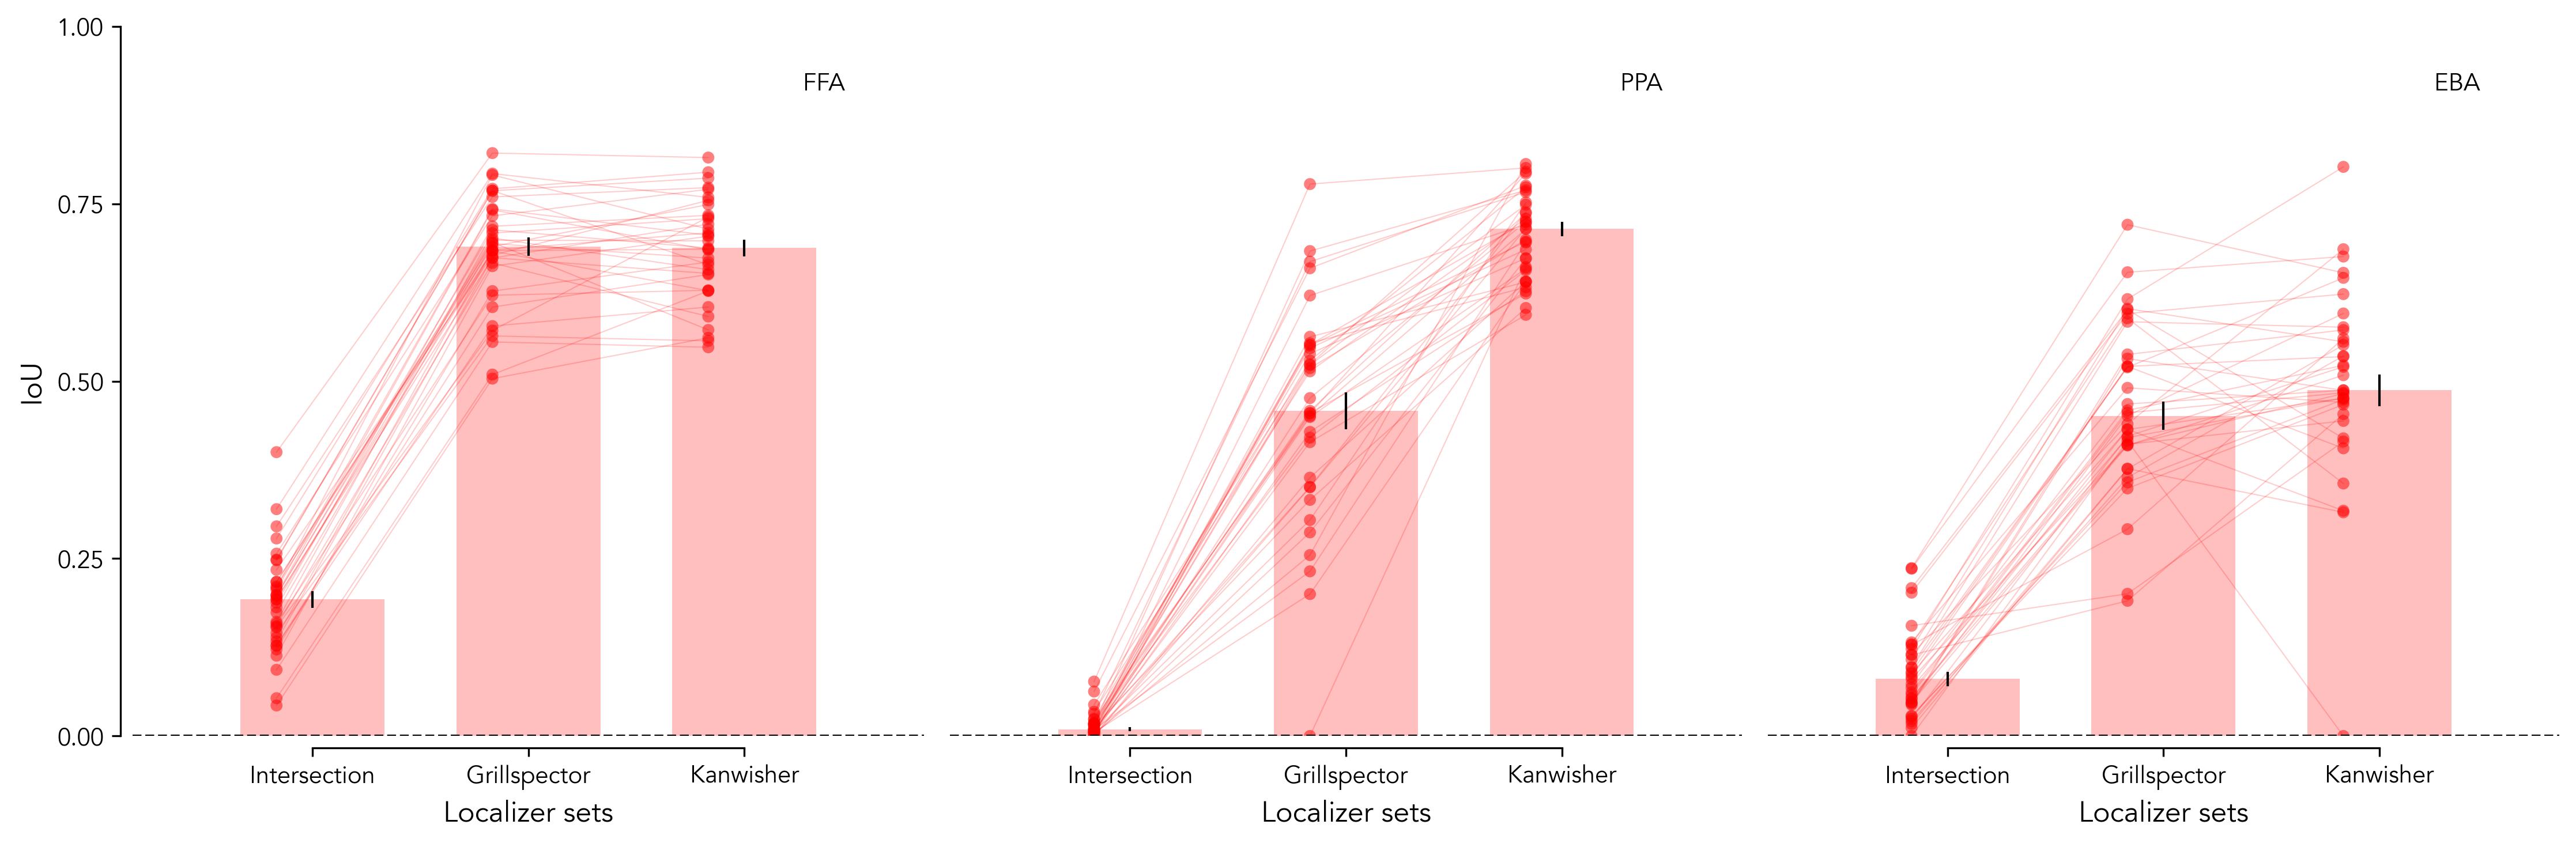

In [ ]:
savefig = True

plot_dir = f'{PLOTS_DIR}/fig4'
os.makedirs(plot_dir, exist_ok=True)

iou_df_path = f'{RESULTS_DIR}/localizer_ious.csv'
ious_df = pd.read_csv(iou_df_path)
results_df = ious_df.copy()

# Group by model, model_froi and fmri_froi, and take median across subjects for the column froi_normed_pearsonr and froi_normed_rdmr
results_df = results_df[
    (results_df['tthreshold'] == 7)
]
results_df_bootstrapmedian = results_df.groupby(
    ['model_name', 'froi', 'model_localizer']
).agg({
    'iou': 'median',
}).reset_index()

frois = ['FFA', 'PPA', 'EBA']
t_threshold = 7

fig, axs = plt.subplots(1, len(frois), figsize=(5*len(frois), 5*1), dpi=300)

x_offset = 0.05
alpha = 0.5
markersize = 25
x = [0, 0.3, 0.6]

for fidx, froi in enumerate(frois):
    results_df_froi = results_df_bootstrapmedian[results_df_bootstrapmedian['froi'] == froi]
    # Get the points
    union_pts = np.array(results_df_froi[results_df_froi['model_localizer'] == 'union']['iou'].tolist())
    grillspector_pts = np.array(results_df_froi[results_df_froi['model_localizer'] == 'grillspector']['iou'].tolist())
    kanwisher_pts = np.array(results_df_froi[results_df_froi['model_localizer'] == 'kanwisher']['iou'].tolist())

    x_union = (np.ones(len(union_pts)) * x[0]) - x_offset
    x_grillspector = (np.ones(len(grillspector_pts)) * x[1]) - x_offset
    x_kanwisher = (np.ones(len(kanwisher_pts)) * x[2]) - x_offset
    axs[fidx].scatter(
        x_union, union_pts, color='red', alpha=alpha, zorder=2,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_grillspector, grillspector_pts, color='red', alpha=alpha, zorder=2,
        edgecolors='none', s=markersize
    )
    axs[fidx].scatter(
        x_kanwisher, kanwisher_pts, color='red', alpha=alpha, zorder=2,
        edgecolors='none', s=markersize
    )
    # connect points with a line
    for i in range(len(union_pts)):
        axs[fidx].plot(
            [x_union[i], x_grillspector[i], x_kanwisher[i]], [union_pts[i], grillspector_pts[i], kanwisher_pts[i]],
            color='red', alpha=0.2, linewidth=0.5, zorder=1
        )
        if (x_grillspector[i] == 0 and x_union[i] == 0) \
            or (x_kanwisher[i] == 0 and x_union[i] == 0):
            # print the model name and froi
            model_name = results_df_froi.iloc[i]['model_name']
            print(f"Model: {model_name}, fROI: {froi}, no category-selective units found for one of the localizers.")

    # Bar plot with median and SEM
    bar_width = 0.2 #0.4
    medians = [np.median(union_pts), np.median(grillspector_pts), np.median(kanwisher_pts)]
    sems = [
        union_pts.std() / np.sqrt(len(union_pts)),
        grillspector_pts.std() / np.sqrt(len(grillspector_pts)),
        kanwisher_pts.std() / np.sqrt(len(kanwisher_pts))
    ]

    axs[fidx].bar(x, medians, yerr=sems, width=bar_width, color=['red', 'red'], alpha=0.25, capsize=0, error_kw={'linewidth': 1})
    # Stats
    # print(f"froi: {froi}, metric: {metric}, layer median: {np.median(union_pts):.3f}, froi median: {np.median(grillspector_pts):.3f}, lesion median: {np.median(kanwisher_pts):.3f}")
    # # Conduct Welch's t-test and mann whitney u test between layer and lesioned points
    # t_value, p_value = scipy.stats.ttest_rel(union_pts, kanwisher_pts)
    # print(f"froi: {froi}, metric: {metric}: t-value: {t_value:.2f}, p-value: {p_value:.2e}")
    # # Conduct Wilcoxon U test
    # u_stat, p_value_mwu = scipy.stats.wilcoxon(union_pts, kanwisher_pts, alternative='two-sided')
    # print(f"froi: {froi}, metric: {metric}: U-statistic: {u_stat:.2f}, p-value (Wilcoxon): {p_value_mwu:.2e}")
    # print()

    # Label fROI
    axs[fidx].text(0.9, 0.9,
                froi,
                horizontalalignment='right', verticalalignment='bottom',
                transform=axs[fidx].transAxes)

    axs[fidx].axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)

    axs[fidx].spines['top'].set_visible(False)
    axs[fidx].spines['right'].set_visible(False)
    axs[fidx].spines['left'].set_position(('outward', 5))
    axs[fidx].spines['bottom'].set_position(('outward', 5))
    axs[fidx].set_yticks([0, 0.25, 0.5, 0.75, 1])
    axs[fidx].spines['left'].set_bounds(0, 1)
    plt.ylim(0, 1.05)
    # plt.tick_params(axis='y', labelleft=False)
    axs[fidx].spines['bottom'].set_bounds(x[0], x[-1])
    axs[fidx].set_xticks(x, ['Intersection', 'Grillspector', 'Kanwisher'])
    axs[fidx].set_xlim(x[0]-0.25, x[-1]+0.25)
    # plt.tick_params(axis='x', labelbottom=False)
    # plt.xlabel('t-threshold of model fROI lesioned', fontsize=12)
    axs[fidx].set_ylabel(f'IoU', fontsize=12)
    axs[fidx].set_xlabel(f'Localizer sets', fontsize=12)

    if froi != 'FFA':
        axs[fidx].spines['left'].set_visible(False)
        # Stop showing y-axis ticks
        axs[fidx].yaxis.set_ticks([])
        axs[fidx].set_ylabel('')

plt.tight_layout()
if savefig:
    raise NotImplementedError("Exploration only")
    plt.savefig(f'{plot_dir}/lesioned_ridge_individualfroi.pdf', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()
plt.close()